# Solutions to selected exercises

Worked solutions for one exercise of each of tutorials 3 to 8. Try the exercise first: the solutions use
nothing beyond what the tutorials introduce.

Run time: about four minutes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

import jax_siesta as js

PSEUDOS = Path("../../examples/pseudos").resolve()
plt.rcParams["figure.dpi"] = 90
EV_ANG3_TO_GPA = 160.21766208

## Tutorial 3, exercise 1: lattice constant with other basis sets

The scan of tutorial 3 as a function, called for three basis sizes.

In [2]:
def silicon(a):
    cell = a * np.array([[0.0, 0.5, 0.5], [0.5, 0.0, 0.5], [0.5, 0.5, 0.0]])
    return js.make_structure(cell, ["Si", "Si"], [[0, 0, 0], [0.25, 0.25, 0.25]], fractional=True)


def birch_murnaghan(v, e0, v0, b0, bp):
    x = (v0 / v) ** (2.0 / 3.0)
    return e0 + 9.0 * v0 * b0 / 16.0 * ((x - 1.0) ** 3 * bp + (x - 1.0) ** 2 * (6.0 - 4.0 * x))


def equation_of_state(basis):
    calc = js.Calculation.from_structure(
        silicon(5.47), PSEUDOS, basis=basis, k_grid=(6, 6, 6), xc_functional="PBE",
        use_symmetry=True, mesh_shape=(32, 32, 32),
    )
    lattice = np.linspace(5.25, 5.70, 7)
    volumes = lattice**3 / 4.0
    energies = np.array([calc.with_structure(silicon(a)).run().energy_ev for a in lattice])
    guess = (energies.min(), volumes[np.argmin(energies)], 0.6, 4.0)
    (e0, v0, b0, bp), _ = curve_fit(birch_murnaghan, volumes, energies, p0=guess)
    return (4.0 * v0) ** (1.0 / 3.0), b0 * EV_ANG3_TO_GPA


for size in ("SZ", "DZP", "TZP"):
    a0, b0 = equation_of_state(size)
    print(f"{size:4s}  a0 = {a0:.4f} Ang   B0 = {b0:6.1f} GPa")

SZ    a0 = 5.6289 Ang   B0 =   70.6 GPa


DZP   a0 = 5.4613 Ang   B0 =   93.9 GPa


TZP   a0 = 5.4648 Ang   B0 =   92.0 GPa


The minimal basis gives a lattice constant 0.17 Å too large and a crystal that is much too soft: its
orbitals cannot adapt to the solid. From DZP on, the changes (0.004 Å, 2 GPa) are small compared with the
error of the functional itself (about 0.04 Å against experiment).

## Tutorial 4, exercise 1: the bands of graphene

A hexagonal cell with two carbon atoms and 15 Å of vacuum. One k-point suffices along the direction
perpendicular to the sheet.

converged: True in 8 iterations


bands 4 and 5 at K relative to the Fermi level (eV): [-0.  0.]


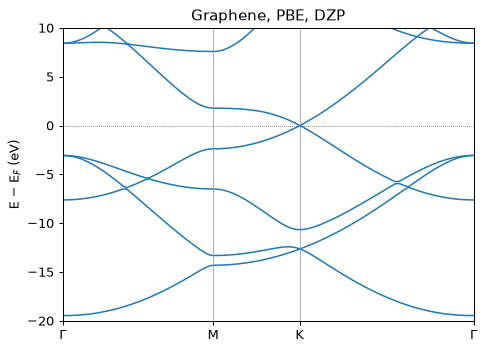

In [3]:
a, c = 2.46, 15.0
cell = np.array([[a, 0.0, 0.0], [-a / 2.0, a * np.sqrt(3.0) / 2.0, 0.0], [0.0, 0.0, c]])
graphene = js.make_structure(cell, ["C", "C"], [[1 / 3, 2 / 3, 0.5], [2 / 3, 1 / 3, 0.5]], fractional=True)
calc = js.Calculation.from_structure(
    graphene, PSEUDOS, basis="DZP", k_grid=(12, 12, 1), xc_functional="PBE",
    mesh_cutoff_ry=150.0, electronic_temp_ha=0.001,
)
res = calc.run()
print("converged:", res.converged, "in", res.n_iterations, "iterations")

path = [("Γ", (0.0, 0.0, 0.0)), ("M", (0.5, 0.0, 0.0)), ("K", (1 / 3, 1 / 3, 0.0)), ("Γ", (0.0, 0.0, 0.0))]
bands = res.band_structure(path, 40)
fig, ax = plt.subplots(figsize=(5.5, 4))
bands.plot(ax=ax)
ax.set_ylim(-20, 10)
ax.set_title("Graphene, PBE, DZP")
fig.tight_layout()

at_k = res.eigenvalues_ev([[1 / 3, 1 / 3, 0.0]])[0, 0]
print("bands 4 and 5 at K relative to the Fermi level (eV):", np.round(at_k[3:5] - res.fermi_level_ev, 4))

The fourth and fifth bands (π and π*) touch at K, at the Fermi level: the Dirac point. Graphene has eight
valence electrons per cell, so four bands are filled and the Fermi level passes exactly through the touching
point. A slightly higher electronic temperature than the default helps the cycle of this semimetal.

## Tutorial 5, exercise 1: bond length and vibration of H₂

equilibrium bond length: 0.748 Ang   (experiment 0.741, converged PBE 0.750)
force constant: 37.2 eV/Ang^2   harmonic frequency: 4483 cm^-1   (experiment 4401)


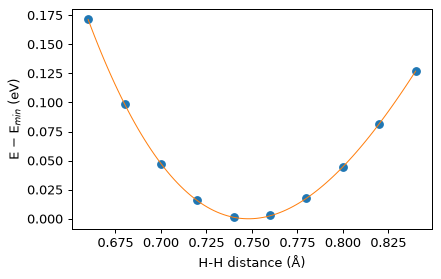

In [4]:
def h2(d):
    return js.make_structure(np.eye(3) * 6.0, ["H", "H"], [[3.0 - d / 2.0, 3.0, 3.0], [3.0 + d / 2.0, 3.0, 3.0]])


calc = js.Calculation.from_structure(
    h2(0.75), PSEUDOS, basis="DZP", xc_functional="PBE", mesh_cutoff_ry=250.0, split_norm_h=0.5
)
lengths = np.linspace(0.66, 0.84, 10)
energies = np.array([calc.with_structure(h2(d)).run().energy_ev for d in lengths])

# A cubic through the points captures the asymmetry of the well; a parabola would bias the minimum.
cubic = np.polyfit(lengths, energies, 3)
d0 = min(np.roots(np.polyder(cubic)).real, key=lambda x: abs(x - 0.75))
k = np.polyval(np.polyder(cubic, 2), d0)  # second derivative at the minimum, eV/Ang^2
omega = 521.47 * np.sqrt(k / (1.008 / 2.0))  # reduced mass m_H / 2; 521.47 converts sqrt(eV/Ang^2/amu) to cm^-1
print(f"equilibrium bond length: {d0:.3f} Ang   (experiment 0.741, converged PBE 0.750)")
print(f"force constant: {k:.1f} eV/Ang^2   harmonic frequency: {omega:.0f} cm^-1   (experiment 4401)")

fig, ax = plt.subplots(figsize=(5, 3.2))
fine = np.linspace(lengths[0], lengths[-1], 100)
ax.plot(lengths, energies - np.polyval(cubic, d0), "o")
ax.plot(fine, np.polyval(cubic, fine) - np.polyval(cubic, d0), "-", lw=0.8)
ax.set_xlabel("H-H distance (Å)")
ax.set_ylabel("E − E$_{min}$ (eV)")
fig.tight_layout()

PBE gives a bond slightly longer than experiment. The well is visibly asymmetric (steeper on the short
side), which is why a cubic is fitted. Without `split_norm_h=0.5` the same calculation gives 0.777 Å: the
default second zeta of hydrogen is too extended (tutorial 7).

## Tutorial 6, exercise 1: binding energy of O₂

The oxygen atom has two unpaired 2p electrons. It is computed in the same box, with the same settings, as the
molecule.

In [5]:
BOX, BOND = 7.0, 1.21
settings = dict(basis="DZP", xc_functional="PBE", mesh_cutoff_ry=150.0, nspin=2)
z = BOX / 2.0
molecule = js.make_structure(np.eye(3) * BOX, ["O", "O"], [[z, z, z - BOND / 2], [z, z, z + BOND / 2]], initial_moments=[1.0, 1.0])
atom = js.make_structure(np.eye(3) * BOX, ["O"], [[z, z, z]], initial_moments=[2.0])

e_mol = js.Calculation.from_structure(molecule, PSEUDOS, **settings).run()
e_atom = js.Calculation.from_structure(atom, PSEUDOS, **settings).run()
print("moment of the atom:", np.round(e_atom.spin_moment[2], 3), " of the molecule:", np.round(e_mol.spin_moment[2], 3))
print(f"binding energy: {2.0 * e_atom.energy_ev - e_mol.energy_ev:.2f} eV   (experiment 5.2 eV; converged PBE about 6.2 eV)")

moment of the atom: 2.0  of the molecule: 2.0
binding energy: 7.67 eV   (experiment 5.2 eV; converged PBE about 6.2 eV)


The result is well above the converged PBE value, itself above experiment. Two known effects act in this
direction, and this notebook does not separate them. First, the basis of the isolated atom lacks the
functions of its partner, so the molecule is described better than the atom (basis-set superposition
error). Second, the ground state of the oxygen atom is not spherical; a calculation in a cubic box can
converge to a state with fractional occupations of the three p orbitals, which lies above the true atomic
ground state. Both make the atom too high in energy and the binding too strong. Atomic reference energies need
more care than this exercise gives them: a larger basis for the atom, and a check of its orbital occupations.

## Tutorial 8, exercise 1: Mulliken charges of water

In [6]:
positions = [[4.0, 4.0, 4.0], [4.766, 4.588, 4.0], [3.234, 4.588, 4.0]]
water = js.make_structure(np.eye(3) * 8.0, ["O", "H", "H"], positions)
res = js.Calculation.from_structure(water, PSEUDOS, basis="DZP", xc_functional="PBE", mesh_cutoff_ry=150.0).run()

dm = np.asarray(res.scf_state.dm_out)[0]
overlap = np.asarray(res.overlap)
src = np.asarray(res.pattern.src_orb)
populations = np.bincount(np.asarray(res.basis.orb_atom)[src], weights=dm * overlap, minlength=3)
valence = np.array([6.0, 1.0, 1.0])
for symbol, pop, zval in zip("OHH", populations, valence):
    print(f"{symbol}: population {pop:.3f}   charge {zval - pop:+.3f}")
print("total:", round(float(populations.sum()), 6))

O: population 5.688   charge +0.312
H: population 1.156   charge -0.156
H: population 1.156   charge -0.156
total: 8.0


The sign is the opposite of what electronegativity suggests: the oxygen comes out *positive*. Mulliken
analysis divides the density by basis function, not by position in space, and the hydrogen orbitals of this
basis are long (4.7 Bohr, more than twice the bond length), so they describe density that physically sits
on the oxygen. This is a known weakness of Mulliken populations with extended basis sets. They depend strongly
on the basis (try `SZ`, and `split_norm_h=0.5`) and are useful for comparing similar systems within one
basis, not as absolute charges.